# [RQ_2 · BỔ SUNG] Thực nghiệm Config C — thời gian, thời tiết và lịch sử lưu lượng
Mục tiêu: dự đoán lưu lượng xe khi biết thêm lưu lượng của các giờ trước. Config C = Config B + 3 đặc trưng lịch sử.

- `lag_24h`: lưu lượng cùng giờ ngày hôm trước
- `lag_168h`: lưu lượng cùng giờ tuần trước
- `mean_24h`: trung bình lưu lượng 24 giờ trước đó, không tính giờ đang dự đoán

Giữ nguyên bốn mô hình và tham số của Config A, B: Linear Regression, Random Forest, Gradient Boosting và MLP. Để so sánh công bằng, A và B được chạy lại trên đúng các giờ mà C dùng.

**Nguồn dữ liệu chung (19/11/2026):** Code đọc dữ liệu đã chuyển sang `src.experiment_data.load_experiment_splits`. `processed` dùng snapshot bàn giao; `raw` dùng cho CV trước điền thiếu; `filled` giữ schema nhãn và học điền từ train. Các output/metrics đang hiển thị là kết quả lịch sử, chưa chạy lại sau thay đổi này.


## 1. Nạp thư viện

In [1]:
from pathlib import Path
from datetime import datetime
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 2. Đọc dữ liệu
Dùng cùng hai file `train.csv` và `validation.csv` như Config A, B.

In [2]:
hien_tai = Path.cwd().resolve()
ung_vien = [hien_tai, *hien_tai.parents, hien_tai / 'metro_interstate_traffic_volume']
du_an = next((p for p in ung_vien
               if (p / 'data/processed/train.csv').is_file()), None)
if du_an is None:
    raise FileNotFoundError('Không thấy data/processed/train.csv. Hãy mở notebook trong thư mục dự án.')
file_train = du_an / 'data/processed/train.csv'
file_val = du_an / 'data/processed/validation.csv'
import sys
if str(du_an) not in sys.path:
    sys.path.insert(0, str(du_an))
from src.experiment_data import load_experiment_splits

data_splits = load_experiment_splits(project_dir=du_an)
train, validation = data_splits["train"], data_splits["validation"]
cot_thoi_gian = ['hour', 'day_of_week', 'month']
cot_ngay_le = ['is_weekend', 'is_holiday'] + [c for c in train.columns if c.startswith('holiday_')]
cot_so_thoi_tiet = ['temp_c', 'rain_1h', 'snow_1h', 'clouds_all']
cot_loai_thoi_tiet = [c for c in train.columns
                     if c.startswith('weather_main_') or c.startswith('weather_description_')]
cot_can_du_doan = 'traffic_volume'
cot_dung = cot_thoi_gian + cot_ngay_le + cot_so_thoi_tiet + cot_loai_thoi_tiet
if train.columns.tolist() != validation.columns.tolist():
    raise ValueError('Hai file không có cùng danh sách cột. Hãy kiểm tra lại dữ liệu.')
for ten, data in [('train', train), ('validation', validation)]:
    if data[cot_dung + [cot_can_du_doan, 'date_time']].isna().any().any():
        raise ValueError(f'{ten} có dữ liệu bị thiếu ở những cột đang dùng.')
    if data.date_time.duplicated().any() or not data.date_time.is_monotonic_increasing:
        raise ValueError(f'{ten} có thời điểm trùng hoặc chưa sắp tăng dần.')
if train.date_time.max() >= validation.date_time.min():
    raise ValueError('Train và validation bị chồng lấn hoặc sai thứ tự thời gian.')
print(f'Train: {len(train):,} dòng | Validation: {len(validation):,} dòng')
print(f'Train kết thúc: {train.date_time.max()} | Validation bắt đầu: {validation.date_time.min()}')
ma_train = hashlib.sha256(file_train.read_bytes()).hexdigest()
ma_val = hashlib.sha256(file_val.read_bytes()).hexdigest()
if (ma_train == 'f7693e70c29feb9502209f5bfbfd67066ad3466b8b718eb242a1d42a931c37e9'
        and ma_val == 'badbebc15f324ac942bd62cc93b95f853b67584646ed097600f536e03513c4e0'):
    print('Hai file dữ liệu trùng với lần chạy Config A, B.')
else:
    print('Lưu ý: dữ liệu khác lần chạy Config A, B, nên không so sánh trực tiếp các con số cũ.')

Train: 28,402 dòng | Validation: 6,086 dòng
Train kết thúc: 2017-05-10 04:00:00 | Validation bắt đầu: 2017-05-10 05:00:00
Hai file dữ liệu trùng với lần chạy Config A, B.


## 3. Tạo đặc trưng lịch sử
Ghép train và validation theo thứ tự thời gian rồi tra lưu lượng theo đúng timestamp, vì dữ liệu có những đoạn bị thiếu giờ. Mỗi giờ chỉ nhìn về các giờ **trước** nó, nên không dùng thông tin tương lai. `mean_24h` cần ít nhất 18 giờ có dữ liệu trong cửa sổ 24 giờ. Giờ nào thiếu một trong ba đặc trưng thì bị loại khỏi thí nghiệm.

In [3]:
cot_lich_su = ['lag_24h', 'lag_168h', 'mean_24h']
so_gio_toi_thieu = 18

toan_bo = pd.concat([train.assign(tap='train'), validation.assign(tap='validation')],
                    ignore_index=True)
luu_luong = toan_bo.set_index('date_time')[cot_can_du_doan].astype('float64')
for so_gio, ten_cot in [(24, 'lag_24h'), (168, 'lag_168h')]:
    toan_bo[ten_cot] = (toan_bo['date_time'] - pd.Timedelta(hours=so_gio)).map(luu_luong)
trung_binh_24h = luu_luong.rolling('24h', closed='left', min_periods=so_gio_toi_thieu).mean()
toan_bo['mean_24h'] = toan_bo['date_time'].map(trung_binh_24h)

du_lich_su = toan_bo[cot_lich_su].notna().all(axis=1)
train_c = toan_bo[du_lich_su & toan_bo['tap'].eq('train')].reset_index(drop=True)
validation_c = toan_bo[du_lich_su & toan_bo['tap'].eq('validation')].reset_index(drop=True)

bang_so_gio = pd.DataFrame({
    'Tập': ['train', 'validation'],
    'Số giờ ban đầu': [len(train), len(validation)],
    'Số giờ đủ lịch sử': [len(train_c), len(validation_c)],
    'Số giờ bị loại': [len(train) - len(train_c), len(validation) - len(validation_c)],
})
display(bang_so_gio)
display(validation_c[['date_time', cot_can_du_doan] + cot_lich_su].head(3))

,Tập,Số giờ ban đầu,Số giờ đủ lịch sử,Số giờ bị loại
0,train,28402,22503,5899
1,validation,6086,6050,36


,date_time,traffic_volume,lag_24h,lag_168h,mean_24h
0,2017-05-10 05:00:00,2920,2921.0,2970.0,3707.000000
1,2017-05-10 06:00:00,5988,6054.0,6054.0,3706.958333
2,2017-05-10 07:00:00,6739,7011.0,6230.0,3704.208333


Kiểm tra lại cách tính trên một giờ bất kỳ của validation: lấy trực tiếp giá trị 24 giờ và 168 giờ trước, và trung bình các giờ trong 24 giờ trước đó.

In [4]:
gio_kiem_tra = validation_c.loc[100, 'date_time']
truoc_24h = luu_luong[(luu_luong.index >= gio_kiem_tra - pd.Timedelta(hours=24))
                      & (luu_luong.index < gio_kiem_tra)]
tinh_tay = {
    'lag_24h': luu_luong[gio_kiem_tra - pd.Timedelta(hours=24)],
    'lag_168h': luu_luong[gio_kiem_tra - pd.Timedelta(hours=168)],
    'mean_24h': truoc_24h.mean(),
}
trong_bang = validation_c.loc[100, cot_lich_su].astype(float).to_dict()
print('Giờ kiểm tra:', gio_kiem_tra)
for ten_cot in cot_lich_su:
    print(f'{ten_cot}: tính tay = {tinh_tay[ten_cot]:.2f} | trong bảng = {trong_bang[ten_cot]:.2f}')
if not np.allclose(list(tinh_tay.values()), [trong_bang[c] for c in cot_lich_su]):
    raise ValueError('Đặc trưng lịch sử tính sai.')

Giờ kiểm tra: 2017-05-14 09:00:00
lag_24h: tính tay = 4082.00 | trong bảng = 4082.00
lag_168h: tính tay = 3270.00 | trong bảng = 3270.00
mean_24h: tính tay = 2979.83 | trong bảng = 2979.83


## 4. Khai báo ba cấu hình đầu vào
A và B giữ nguyên cách xử lý như hai notebook trước. C thêm bước chuẩn hóa `StandardScaler` cho 3 cột lịch sử, vì giá trị của chúng lên tới vài nghìn, MLP và Linear Regression học tốt hơn khi các cột có cùng thang đo. Bộ chuẩn hóa nằm trong `Pipeline` nên chỉ học trung bình và độ lệch chuẩn từ train.

In [5]:
xu_ly_a = [
    ('thoi_gian', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cot_thoi_gian),
    ('ngay_le', 'passthrough', cot_ngay_le),
]
xu_ly_b = xu_ly_a + [
    ('thoi_tiet_so', StandardScaler(), cot_so_thoi_tiet),
    ('loai_thoi_tiet', 'passthrough', cot_loai_thoi_tiet),
]
xu_ly_c = xu_ly_b + [
    ('lich_su', StandardScaler(), cot_lich_su),
]
cac_cau_hinh = {
    'A': (cot_thoi_gian + cot_ngay_le, ColumnTransformer(xu_ly_a)),
    'B': (cot_thoi_gian + cot_ngay_le + cot_so_thoi_tiet + cot_loai_thoi_tiet, ColumnTransformer(xu_ly_b)),
    'C': (cot_thoi_gian + cot_ngay_le + cot_so_thoi_tiet + cot_loai_thoi_tiet + cot_lich_su,
          ColumnTransformer(xu_ly_c)),
}
for ten, (cot, _) in cac_cau_hinh.items():
    print(f'Config {ten}: {len(cot)} cột đầu vào')

Config A: 17 cột đầu vào
Config B: 71 cột đầu vào
Config C: 74 cột đầu vào


## 5. Khai báo bốn mô hình (giữ nguyên tham số của Config A, B)

In [6]:
cac_mo_hinh = {
    'Linear Regression': LinearRegression(),

    'Random Forest': RandomForestRegressor(
        n_estimators=200, max_depth=16, min_samples_leaf=3,
        random_state=42, n_jobs=2),

    'Gradient Boosting': GradientBoostingRegressor(
        n_estimators=300, learning_rate=0.05, max_depth=3,
        min_samples_leaf=3, random_state=42),

    'MLP': TransformedTargetRegressor(
        regressor=MLPRegressor(
            hidden_layer_sizes=(64, 32), alpha=0.0001,
            learning_rate_init=0.001, batch_size=256,
            max_iter=500, random_state=42),
        transformer=StandardScaler()),
}

## 6. Huấn luyện và đánh giá
Cả 12 lượt (3 cấu hình × 4 mô hình) dùng cùng giờ train, cùng giờ validation và cùng tham số. Chỉ có danh sách cột đầu vào thay đổi.

In [7]:
y_train_c = train_c[cot_can_du_doan]
y_val_c = validation_c[cot_can_du_doan]
ket_qua = []
du_doan_cac_mo_hinh = {}
for cau_hinh, (cot, xu_ly) in cac_cau_hinh.items():
    for ten, mo_hinh in cac_mo_hinh.items():
        quy_trinh = Pipeline([('xu_ly', clone(xu_ly)), ('mo_hinh', clone(mo_hinh))])
        quy_trinh.fit(train_c[cot], y_train_c)
        du_doan = np.clip(quy_trinh.predict(validation_c[cot]), 0, None)
        du_doan_cac_mo_hinh[(cau_hinh, ten)] = du_doan
        ket_qua.append({
            'config': cau_hinh,
            'model': ten,
            'split': 'validation',
            'n_features': len(cot),
            'n_train': len(train_c),
            'n_validation': len(validation_c),
            'MAE': mean_absolute_error(y_val_c, du_doan),
            'RMSE': np.sqrt(mean_squared_error(y_val_c, du_doan)),
            'R2': r2_score(y_val_c, du_doan),
        })

bang_ket_qua = pd.DataFrame(ket_qua).sort_values(['config', 'MAE']).reset_index(drop=True)
display(HTML(bang_ket_qua.to_html(
    index=False,
    formatters={
        'MAE': '{:.3f}'.format,
        'RMSE': '{:.3f}'.format,
        'R2': '{:.4f}'.format,
    }
)))

config,model,split,n_features,n_train,n_validation,MAE,RMSE,R2
A,MLP,validation,17,22503,6050,262.448,385.083,0.9616
A,Random Forest,validation,17,22503,6050,318.936,474.655,0.9416
A,Gradient Boosting,validation,17,22503,6050,432.658,584.985,0.9113
A,Linear Regression,validation,17,22503,6050,563.322,759.559,0.8505
B,MLP,validation,71,22503,6050,279.097,403.343,0.9578
B,Random Forest,validation,71,22503,6050,316.102,473.262,0.9420
B,Gradient Boosting,validation,71,22503,6050,424.367,573.843,0.9147
B,Linear Regression,validation,71,22503,6050,564.547,760.202,0.8502
C,MLP,validation,74,22503,6050,218.389,323.063,0.9730
C,Random Forest,validation,74,22503,6050,227.653,398.378,0.9589


## 7. So sánh A, B, C
Mức giảm dương nghĩa là C tốt hơn B (sai số nhỏ hơn).

In [8]:
thu_tu_mo_hinh = ['MLP', 'Random Forest', 'Gradient Boosting', 'Linear Regression']
bang_mae = bang_ket_qua.pivot(index='model', columns='config', values='MAE').loc[thu_tu_mo_hinh]
bang_rmse = bang_ket_qua.pivot(index='model', columns='config', values='RMSE').loc[thu_tu_mo_hinh]
so_sanh = pd.DataFrame({
    'MAE A': bang_mae['A'],
    'MAE B': bang_mae['B'],
    'MAE C': bang_mae['C'],
    'MAE giảm (B → C)': bang_mae['B'] - bang_mae['C'],
    '% MAE giảm': (bang_mae['B'] - bang_mae['C']) / bang_mae['B'] * 100,
    'RMSE B': bang_rmse['B'],
    'RMSE C': bang_rmse['C'],
    'RMSE giảm (B → C)': bang_rmse['B'] - bang_rmse['C'],
    '% RMSE giảm': (bang_rmse['B'] - bang_rmse['C']) / bang_rmse['B'] * 100,
})
display(so_sanh.round(2))

,MAE A,MAE B,MAE C,MAE giảm (B → C),% MAE giảm,RMSE B,RMSE C,RMSE giảm (B → C),% RMSE giảm
model,,,,,,,,,
MLP,262.45,279.10,218.39,60.71,21.75,403.34,323.06,80.28,19.90
Random Forest,318.94,316.10,227.65,88.45,27.98,473.26,398.38,74.88,15.82
Gradient Boosting,432.66,424.37,265.22,159.14,37.50,573.84,439.63,134.21,23.39
Linear Regression,563.32,564.55,328.73,235.82,41.77,760.20,513.93,246.28,32.40


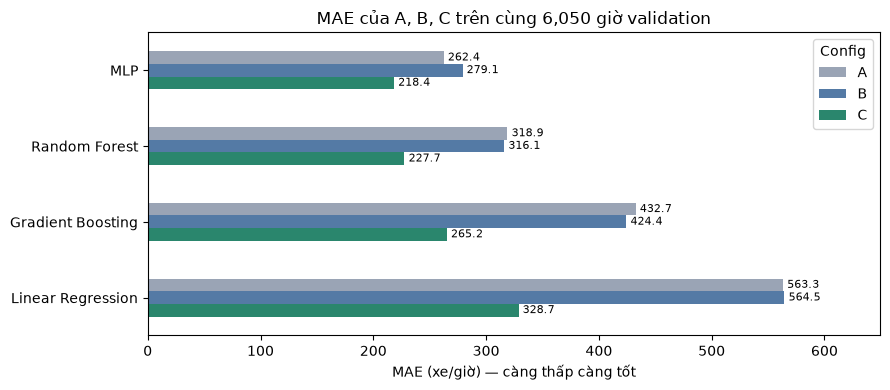

Hình đã lưu tại: /workspaces/SGU_HocMay_2026-2027/metro_interstate_traffic_volume/experiments/17-11-2026_ConfigC_4Model-Hao/ConfigABC_MAE_20261117_075339_350294.png


In [9]:
thu_muc_ket_qua = du_an / 'experiments' / '17-11-2026_ConfigC_4Model-Hao'
thu_muc_ket_qua.mkdir(parents=True, exist_ok=True)
ax = bang_mae[['A', 'B', 'C']].plot.barh(color=['#9AA4B5', '#547AA5', '#2A866D'], figsize=(9, 4))
for cot_thanh in ax.containers:
    ax.bar_label(cot_thanh, fmt='%.1f', padding=3, fontsize=8)
ax.invert_yaxis()
ax.set_xlim(0, bang_mae.max().max() * 1.15)
ax.set_xlabel('MAE (xe/giờ) — càng thấp càng tốt')
ax.set_ylabel('')
ax.set_title(f'MAE của A, B, C trên cùng {len(validation_c):,} giờ validation')
ax.legend(title='Config')
ax.figure.tight_layout()
ten_hinh_mae = thu_muc_ket_qua / f"ConfigABC_MAE_{datetime.now():%Y%m%d_%H%M%S_%f}.png"
ax.figure.savefig(ten_hinh_mae, dpi=150, bbox_inches='tight')
plt.show()
print('Hình đã lưu tại:', ten_hinh_mae)

## 8. Vẽ hình so sánh — Config C, 72 giờ đầu validation

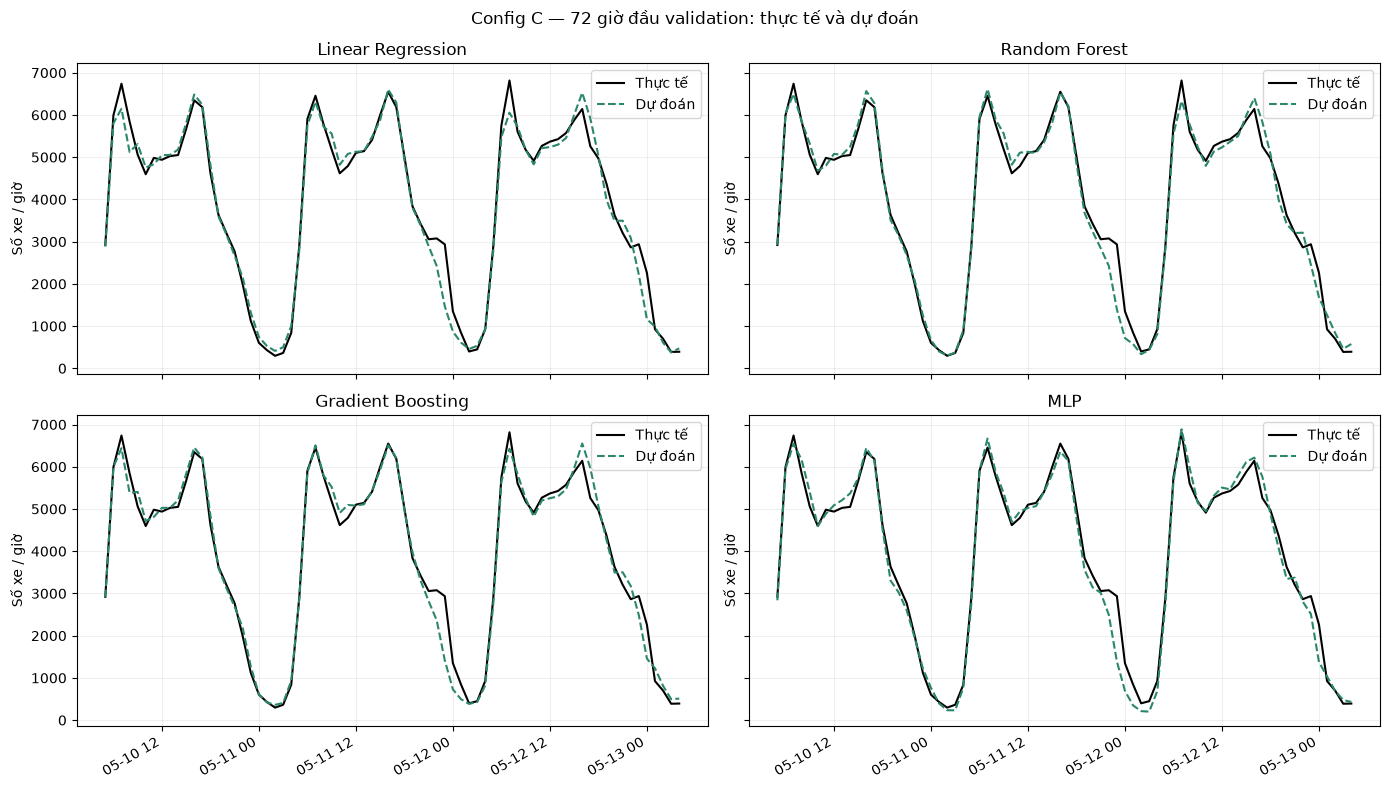

Hình đã lưu tại: /workspaces/SGU_HocMay_2026-2027/metro_interstate_traffic_volume/experiments/17-11-2026_ConfigC_4Model-Hao/ConfigC_lich_su_20261117_080203_847598.png


In [11]:
mask_72h = validation_c.date_time < validation_c.date_time.min() + pd.Timedelta(hours=72)
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True, sharey=True)
for ax, ten in zip(axes.flat, cac_mo_hinh):
    du_doan = du_doan_cac_mo_hinh[('C', ten)]
    ax.plot(validation_c.loc[mask_72h, 'date_time'], y_val_c.loc[mask_72h],
            color='black', label='Thực tế')
    ax.plot(validation_c.loc[mask_72h, 'date_time'], du_doan[mask_72h.to_numpy()],
            color='#2A866D', linestyle='--', label='Dự đoán')
    ax.set_title(ten)
    ax.set_ylabel('Số xe / giờ')
    ax.grid(alpha=0.2)
    ax.legend()
fig.suptitle('Config C — 72 giờ đầu validation: thực tế và dự đoán')
fig.autofmt_xdate()
fig.tight_layout()
ten_hinh = thu_muc_ket_qua / f"ConfigC_lich_su_{datetime.now():%Y%m%d_%H%M%S_%f}.png"
thu_muc_ket_qua.mkdir(parents=True, exist_ok=True)
fig.savefig(ten_hinh, dpi=150, bbox_inches='tight')
plt.show()
print('Hình đã lưu tại:', ten_hinh)

## 9. Lưu kết quả

In [12]:
file_ket_qua = thu_muc_ket_qua / 'V3_ConfigC_Hao_metrics.csv'
bang_ket_qua.to_csv(file_ket_qua, index=False)
print('Bảng kết quả đã lưu tại:', file_ket_qua)

Bảng kết quả đã lưu tại: /workspaces/SGU_HocMay_2026-2027/metro_interstate_traffic_volume/experiments/17-11-2026_ConfigC_4Model-Hao/V3_ConfigC_Hao_metrics.csv


<!-- proposal-assessment -->
## Đánh giá đối với proposal — RQ_2

**Vai trò: BỔ SUNG.** Mã đối chiếu: [E12](../../docs/experiment_tracking/EXPERIMENTS_BY_DATE_AND_RQ.md). Đây là hướng mở rộng/kiểm tra bổ sung, không thay thế đối chứng chính A→B của RQ_2.

- **Câu hỏi:** Thêm 3 đặc trưng lịch sử giúp từng pipeline bao nhiêu trên cùng train/validation?
- **Đánh giá:** Bổ sung bằng chứng history bằng cách chạy lại A17/B71/C74 cùng cohort. Với MLP, B→C giảm MAE 279,097→218,389 và RMSE 403,343→323,063; có ích trong nhánh pipeline của Hào.
- **Giới hạn kết luận:** C74 khác C30 của Vũ/Huy. Chỉ so A/B/C bên trong cùng protocol; không dùng chênh với RF C30 hoặc MLP A+H20 để cô lập riêng thuật toán.
- **Bằng chứng:** [E12: V3_ConfigC_Hao_metrics.csv](V3_ConfigC_Hao_metrics.csv).

Đánh giá trên dựa vào hiện vật lịch sử đã đối chứng, không phải kết quả chạy mới. Code lấy dữ liệu đã được chuẩn hóa; chưa huấn luyện lại hoặc chấm test.
